# TASK 01 — Temporal Feature Engineering & Data Consistency Review

**Purpose.** Add six temporal features to the order-level Olist research dataset and verify that original data and the `is_late` target remain unchanged.

**Data policy.** Preserve all orders and existing columns. Do not impute missing timestamps, remove statistical outliers, or redefine the target. The team maintains **one canonical file**, `data/processed/research_data.csv`, updated only after successful validation and an explicit export decision.

**Reproducibility.** Feature assignment is *idempotent*: rerunning the notebook replaces existing feature columns rather than adding duplicates. To inspect the original 28-column Stage 1 snapshot after an update, use the Git history.

## 1. Load dataset and inspect the baseline

Load the canonical CSV and check row count, column count, unique `order_id`, and target distribution. A single row must represent one order. Reading this file does **not** modify it. Paths work when the notebook is launched from either the repository root or its `notebooks/` directory.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path("data/processed/research_data.csv"), Path("../data/processed/research_data.csv")]
csv_path = next((p.resolve() for p in candidates if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError("Cannot locate data/processed/research_data.csv")

df = pd.read_csv(csv_path)
required = ["order_id", "order_status", "is_late", "order_purchase_timestamp",
            "order_approved_at", "order_delivered_customer_date", "order_estimated_delivery_date"]
assert set(required).issubset(df.columns), "Required columns are missing"
assert df["order_id"].notna().all() and df["order_id"].is_unique, "Order IDs must be complete and unique"
assert df["is_late"].dropna().isin([0, 1]).all(), "Target contains unexpected labels"

new_features = ["purchase_hour", "purchase_is_weekend", "estimated_window_days",
                "approval_delay_hours", "actual_delivery_days", "delivery_delay_days"]
df_enhanced = df.copy()
print(f"Input: {csv_path.name} | Orders: {len(df):,} | Columns: {df.shape[1]}")
display(df["is_late"].value_counts(dropna=False).rename_axis("is_late").to_frame("orders"))

Input: research_data.csv | Orders: 99,441 | Columns: 28


,orders
is_late,
0.0,89936
1.0,6534
NaN,2971


## 2. Engineer six temporal features

**Calendar-day differences** remove the time-of-day component with `.dt.normalize()`. **Continuous durations** preserve seconds, then convert to hours (÷ 3,600) or days (÷ 86,400).

| Feature | Definition / formula | Unit |
|---|---|---|
| `purchase_hour` | Hour of purchase timestamp | 0–23 |
| `purchase_is_weekend` | 1 for Saturday/Sunday, otherwise 0 | Binary |
| `estimated_window_days` | Estimated delivery **date** − purchase **date** | Calendar days |
| `approval_delay_hours` | Approval timestamp − purchase timestamp | Hours |
| `actual_delivery_days` | Delivery timestamp − purchase timestamp | Continuous days |
| `delivery_delay_days` | Delivery **date** − estimated delivery **date** | Calendar days |

For `delivery_delay_days`, **negative** means early delivery, **zero** means on the estimated date, and **positive** means late delivery. Existing `promised_days` (measured from approval date) is preserved and is not interchangeable with `estimated_window_days`.

In [2]:
timestamp_cols = {
    "purchase": "order_purchase_timestamp",
    "approved": "order_approved_at",
    "delivered": "order_delivered_customer_date",
    "estimated": "order_estimated_delivery_date",
}
t = {k: pd.to_datetime(df[col], errors="coerce") for k, col in timestamp_cols.items()}
for key, col in timestamp_cols.items():
    assert t[key].isna().equals(df[col].isna()), f"Unparseable timestamp in {col}"
p, a, d, e = (t[k] for k in timestamp_cols)

df_enhanced["purchase_hour"] = p.dt.hour
df_enhanced["purchase_is_weekend"] = (p.dt.dayofweek >= 5).astype("Int64").where(p.notna())
df_enhanced["estimated_window_days"] = (e.dt.normalize() - p.dt.normalize()).dt.days
df_enhanced["approval_delay_hours"] = (a - p).dt.total_seconds() / 3600
df_enhanced["actual_delivery_days"] = (d - p).dt.total_seconds() / 86400
df_enhanced["delivery_delay_days"] = (d.dt.normalize() - e.dt.normalize()).dt.days

display(df_enhanced[["order_id"] + new_features].head())

,order_id,purchase_hour,purchase_is_weekend,estimated_window_days,approval_delay_hours,actual_delivery_days,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,10,0,16,0.178333,8.436574,-8.0
1,53cdb2fc8bc7dce0b6741e2150273451,20,0,20,30.713889,13.782037,-6.0
2,47770eb9100c2d0c44946d9cf07ec65d,8,0,27,0.276111,9.394213,-18.0
3,949d5b44dbf5de918fe9c16f97b45f8a,19,1,27,0.298056,13.208750,-13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,21,0,13,1.030556,2.873877,-10.0


## 3. Missingness and duration plausibility

Summarize observed values, missing percentages, minima, maxima, and counts of negative and zero values. Missing values must correspond to missing source timestamps. Negative values are **expected** for `delivery_delay_days` (early delivery), but not for the other three duration measures. Report suspicious durations without changing them.

In [3]:
duration_cols = new_features[2:]
summary = df_enhanced[new_features].agg(["count", "min", "max"]).T
summary["missing"] = df_enhanced[new_features].isna().sum()
summary["missing_pct"] = (df_enhanced[new_features].isna().mean() * 100).round(2)
summary["negative"] = df_enhanced[new_features].lt(0).sum()
summary["zero"] = df_enhanced[new_features].eq(0).sum()
display(summary)

for col, sources in {
    "purchase_hour": (p,), "purchase_is_weekend": (p,),
    "estimated_window_days": (p, e), "approval_delay_hours": (p, a),
    "actual_delivery_days": (p, d), "delivery_delay_days": (d, e),
}.items():
    expected_missing = pd.concat([s.isna() for s in sources], axis=1).any(axis=1)
    assert df_enhanced[col].isna().equals(expected_missing), f"Unexpected missingness: {col}"
assert all(df_enhanced[c].dropna().ge(0).all() for c in duration_cols[:-1]), "Negative duration found"
assert df_enhanced["purchase_hour"].dropna().between(0, 23).all()
assert df_enhanced["purchase_is_weekend"].dropna().isin([0, 1]).all()
print("Missingness and duration checks passed.")

,count,min,max,missing,missing_pct,negative,zero
purchase_hour,99441.0,0.000000,23.000000,0,0.00,0,2394
purchase_is_weekend,99441.0,0.000000,1.000000,0,0.00,0,76594
estimated_window_days,99441.0,2.000000,156.000000,0,0.00,0,0
approval_delay_hours,99281.0,0.000000,4509.180556,160,0.16,0,1296
actual_delivery_days,96476.0,0.533414,209.628611,2965,2.98,0,0
delivery_delay_days,96476.0,-147.000000,188.000000,2965,2.98,88649,1292


Missingness and duration checks passed.


## 4. IQR outlier screening

Tukey's 1.5 × IQR fences identify unusually low or high durations:

\[
IQR = Q_3 - Q_1, \qquad L = Q_1 - 1.5\,IQR, \qquad U = Q_3 + 1.5\,IQR
\]

A value is flagged if it is below \(L\) or above \(U\). **An outlier flag is not proof of an error.** Preserve every original observation; do not cap, replace, or delete flagged values.

In [4]:
outlier_rows = []
for col in duration_cols:
    values = df_enhanced[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flag = ~values.between(lower, upper)
    outlier_rows.append({"feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                         "lower_fence": lower, "upper_fence": upper,
                         "outliers": int(flag.sum()), "outlier_pct": round(flag.mean() * 100, 2)})
outlier_report = pd.DataFrame(outlier_rows).set_index("feature")
display(outlier_report.round(2))

,Q1,Q3,IQR,lower_fence,upper_fence,outliers,outlier_pct
feature,,,,,,,
estimated_window_days,19.00,29.00,10.00,4.00,44.00,2464,2.48
approval_delay_hours,0.22,14.58,14.37,-21.33,36.13,9141,9.21
actual_delivery_days,6.77,15.72,8.95,-6.66,29.15,4899,5.08
delivery_delay_days,-17.00,-7.00,10.00,-32.00,8.00,4301,4.46


## 5. Visualize temporal distributions

A **histogram** shows distribution shape, concentration, and skewness. A **boxplot** shows median, quartiles, and potential outliers. Both views use all non-missing observations. The optional 99th-percentile view helps reveal the central distribution when a few very large values compress the histogram; it does **not** change the underlying dataset.

Categorical/binary features (`purchase_hour` and `purchase_is_weekend`) are not included in these duration plots; grouped late-delivery EDA is assigned to TASK 02.

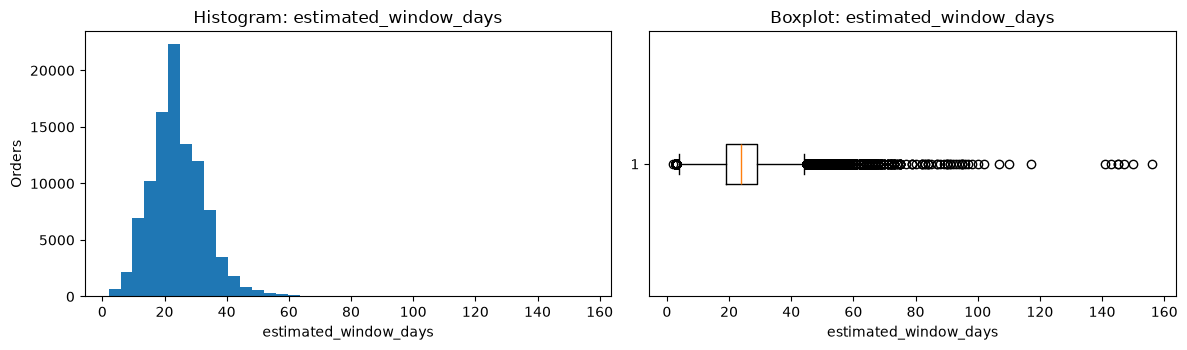

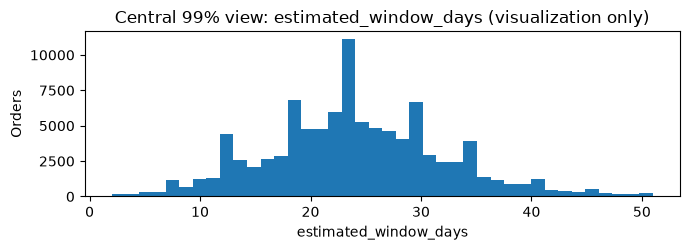

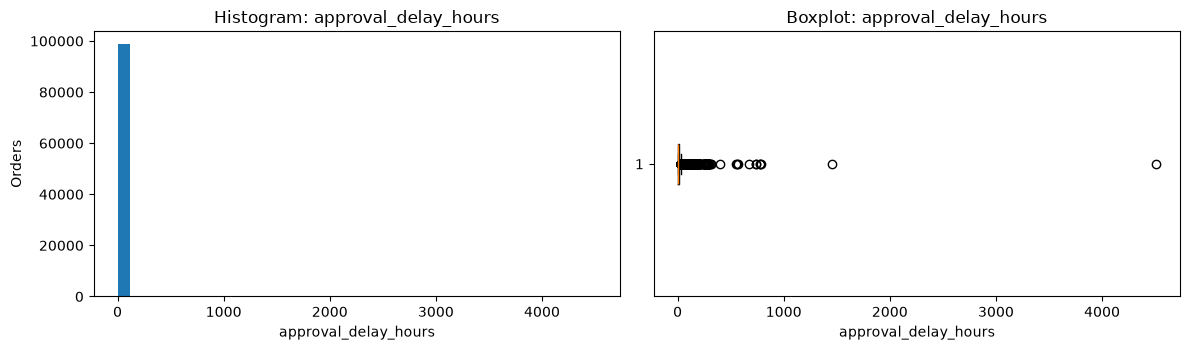

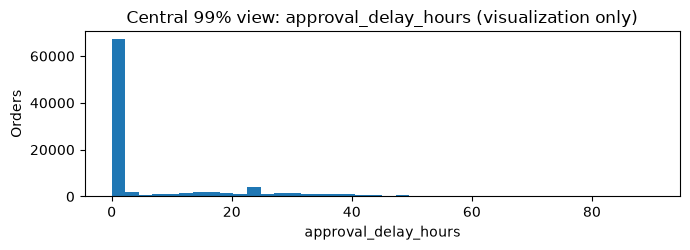

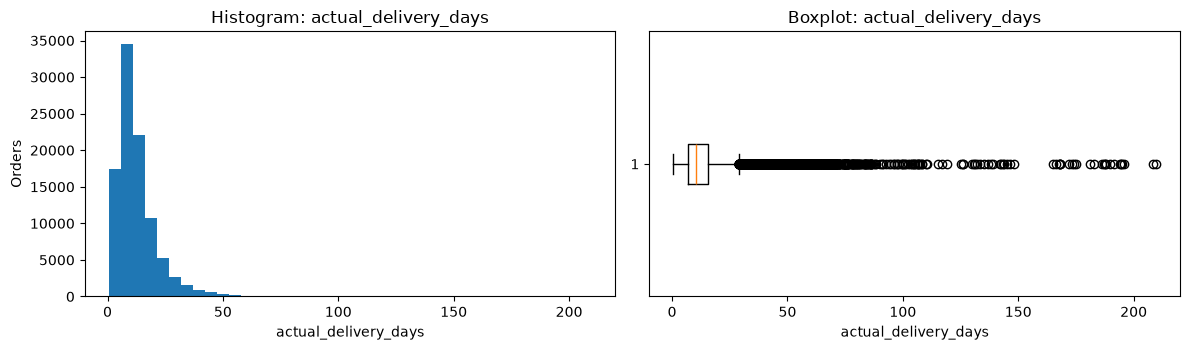

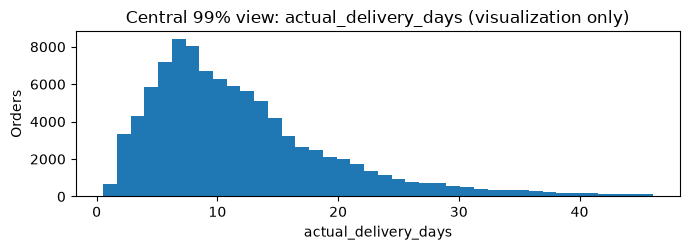

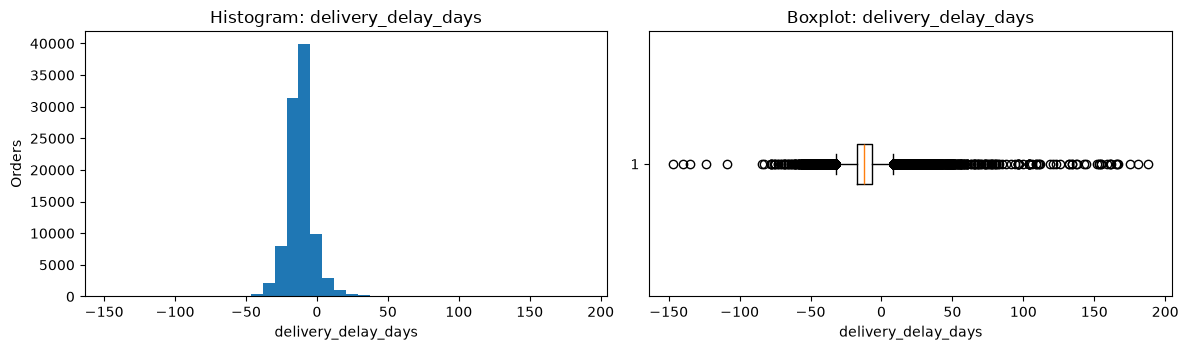

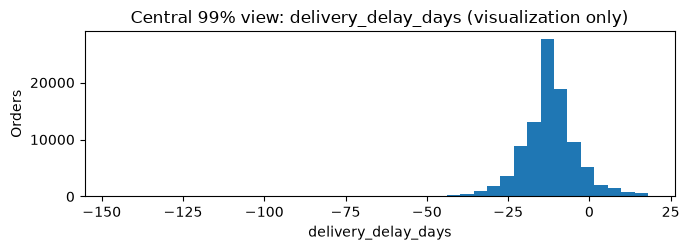

In [5]:
SHOW_CENTRAL_ZOOM = True
for col in duration_cols:
    values = df_enhanced[col].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    axes[0].hist(values, bins=40)
    axes[0].set(title=f"Histogram: {col}", xlabel=col, ylabel="Orders")
    axes[1].boxplot(values, orientation="horizontal")
    axes[1].set(title=f"Boxplot: {col}", xlabel=col)
    plt.tight_layout()
    plt.show()

    if SHOW_CENTRAL_ZOOM:
        upper = values.quantile(0.99)
        fig, ax = plt.subplots(figsize=(7, 2.6))
        ax.hist(values[values <= upper], bins=40)
        ax.set(title=f"Central 99% view: {col} (visualization only)", xlabel=col, ylabel="Orders")
        plt.tight_layout()
        plt.show()

## 6. Verify target consistency and inspect extreme deliveries

For every **labeled** order, the existing Stage 1 definition must satisfy:

\[
\mathrm{is\_late} = \mathbf{1}(\mathrm{delivery\_delay\_days} > 0)
\]

The comparison uses **calendar dates**, not continuous duration. Orders with missing target remain unlabeled. `delivery_delay_days` and `actual_delivery_days` contain post-delivery information and **must not** be used as predictors at purchase time.

Inspect deliveries taking more than 180 days as a *descriptive quality check*, without automatically labeling them as errors.

In [6]:
labeled = df_enhanced[df_enhanced["is_late"].isin([0, 1])]
assert labeled["delivery_delay_days"].notna().all(), "Labeled order missing delivery delay"
target_mismatches = labeled["is_late"].ne(labeled["delivery_delay_days"].gt(0).astype(int))
assert not target_mismatches.any(), "Inconsistent is_late target"
print(f"Valid target: {len(labeled):,} | Target mismatches: {target_mismatches.sum():,}")

extreme = df_enhanced[df_enhanced["actual_delivery_days"] > 180].copy()
extreme["delivery_date"] = d.loc[extreme.index].dt.date
print(f"Actual delivery duration >180 days: {len(extreme)} orders")
display(extreme["delivery_date"].value_counts().rename_axis("delivery_date").to_frame("orders").head(10))

Valid target: 96,470 | Target mismatches: 0
Actual delivery duration >180 days: 14 orders


,orders
delivery_date,
2017-09-19,10
2018-07-13,1
2018-09-19,1
2017-08-28,1
2017-11-16,1


## 7. Verify preservation of source data

All input columns and values must remain unchanged in memory. The only permitted additions are the six temporal features; if they already exist in the input CSV, they are recalculated **by name**, not duplicated. The report compares order counts, unique keys, valid labels, late orders, and missing targets. A change from **28 to 34 columns** on the first run is expected.

In [7]:
assert len(df_enhanced) == len(df)
assert df_enhanced["order_id"].is_unique
assert set(df_enhanced.columns) == set(df.columns).union(new_features)

# Preserve pre-existing source columns; previously computed temporal features may be refreshed on reruns.
source_cols = df.columns.difference(new_features, sort=False)
pd.testing.assert_frame_equal(df[source_cols], df_enhanced[source_cols], check_dtype=True)
assert df_enhanced["is_late"].equals(df["is_late"])

metrics = {
    "total_orders": lambda x: len(x),
    "unique_order_id": lambda x: x["order_id"].nunique(),
    "valid_target": lambda x: x["is_late"].isin([0, 1]).sum(),
    "late_orders": lambda x: x["is_late"].eq(1).sum(),
    "missing_target": lambda x: x["is_late"].isna().sum(),
}
comparison = pd.DataFrame({"Original": {k: f(df) for k, f in metrics.items()},
                           "Enhanced": {k: f(df_enhanced) for k, f in metrics.items()}})
comparison["Match"] = comparison["Original"].eq(comparison["Enhanced"])
assert comparison["Match"].all()
display(comparison)
print(f"Columns: {df.shape[1]} → {df_enhanced.shape[1]} | Consistency passed")

,Original,Enhanced,Match
total_orders,99441,99441,True
unique_order_id,99441,99441,True
valid_target,96470,96470,True
late_orders,6534,6534,True
missing_target,2971,2971,True


Columns: 28 → 34 | Consistency passed


## 8. Export the canonical CSV (manual, guarded)

The final output is the **existing** `research_data.csv`; do not create a separate `research_data_v2.csv`. Leave `EXPORT = False` while reviewing the notebook.

Before turning it on, confirm that the current Git branch is `feat/temporal-feature-enhancement`, the working tree is appropriate, and all checks above passed. The export cell independently repeats core validation, writes to a temporary CSV, re-reads and checks it, and **only then** replaces the local canonical CSV. Git keeps the prior committed Stage 1 version. Export does not merge anything into `main`.

**Important:** A Stage 1 notebook that regenerates the 28-column CSV may overwrite these new features; to reproduce the enhanced dataset, run Stage 1 preparation **before** this notebook.

In [ ]:
EXPORT = False  # Change to True ONLY after validation and branch review.

if EXPORT:
    import os
    import subprocess
    import tempfile

    branch = subprocess.check_output(["git", "branch", "--show-current"], cwd=csv_path.parent, text=True).strip()
    assert branch == "feat/temporal-feature-enhancement", f"Unexpected Git branch: {branch}"
    assert len(df_enhanced) == len(df) and df_enhanced["order_id"].is_unique
    assert comparison["Match"].all() and not target_mismatches.any()
    assert set(new_features).issubset(df_enhanced.columns)
    pd.testing.assert_frame_equal(df[source_cols], df_enhanced[source_cols], check_dtype=True)

    # Write and verify a temporary CSV before replacing the canonical file.
    with tempfile.NamedTemporaryFile(mode="w", suffix=".csv", prefix="research_data_checked_",
                                     dir=csv_path.parent, delete=False, encoding="utf-8", newline="") as tmp:
        temp_path = Path(tmp.name)
    try:
        df_enhanced.to_csv(temp_path, index=False)
        saved = pd.read_csv(temp_path)
        assert saved.shape == df_enhanced.shape
        assert saved["order_id"].equals(df_enhanced["order_id"])
        assert saved["is_late"].equals(df_enhanced["is_late"])
        assert set(new_features).issubset(saved.columns)
        pd.testing.assert_frame_equal(saved[source_cols], df[source_cols], check_dtype=False)
        os.replace(temp_path, csv_path)
        print("Canonical dataset updated and verified:", csv_path)
    finally:
        temp_path.unlink(missing_ok=True)
else:
    print("Export skipped: canonical research_data.csv remains unchanged.")

Canonical dataset updated and verified: C:\Users\LENOVO\Downloads\Group5_STAT3013.R11-feat-research-data-eda\Group5_STAT3013.R11\data\processed\research_data.csv
